# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
from project_support.csv_runs import load_notebook_csv_path

## df

In [2]:
df = pd.read_parquet(r'bert_trainset_squared_25.gzip')
print(df.shape)
df_uniques = [val for val in df['position_state'].unique()]
df['position_state_id'] = df.groupby('position_state').transform('ngroup')
print(len(df_uniques))
df.head(2)

(13134, 11)
947


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.75,"[0.7, 0.89]",0.070249,"[-0.04648240511472945, -0.103916968250235]",-0.721635,"[-0.3147863504974622, -0.949162553802292]",XYCOAOWPMOWWNFTUVQEX,864,1.022175,973.0,1
1,0.80,"[0.699, 0.885]",0.075165,"[-0.02934323295077368, -0.09384195961539277]",2.351097,"[-0.3093471255142001, -0.9509491868318211]",XYCOAOWPMOWWNFTUKDZD,863,1.021119,968.0,1


In [3]:
df[['position_state_id', 'position_state']].nunique()

position_state_id    947
position_state       947
dtype: int64

## apd

In [4]:
apd = pd.read_parquet('legacy/datasets/apd_full.gzip')
print(apd.shape)
apd_uniques = [val for val in apd['position_state'].unique()]
print(len(apd_uniques))
apd.head(2)

(1002001, 80)
1057


,X,Y,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,obj_3_pos,...,dist_to_obj_17,dist_to_obj_18,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24,position_state,mean_distance
0,0.000,0.0,"[0.0, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.877006,1.040242,1.256338,1.000670,1.020126,1.106586,1.244571,1.398089,COQVSOAUMTASMTUPCRFN,0.266292
1,0.001,0.0,"[0.001, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.876157,1.039548,1.255733,0.999671,1.019146,1.105682,1.243779,1.397373,COQVSOAUMTASMTUPCRFN,0.265635


## ps_to_psid

In [5]:
with open('ps_to_psid.pkl', 'rb') as file:
    ps_to_psid = pickle.load(file)

In [6]:
apd['position_state_id'] = [ps_to_psid[k] for k in apd['position_state']]

## cossim

In [7]:
coss = pd.read_csv(load_notebook_csv_path('bert_squared', "cosine_similarity_matrix.csv"))
print(coss.shape)
coss.head(5)

(948, 948)


,0,1,2,3,4,5,6,7,8,9,...,938,939,940,941,942,943,944,945,946,947
0,1.000000,0.028674,0.035668,0.055362,0.007267,-0.008802,-0.016504,-0.028359,0.026250,-0.009555,...,0.069556,0.011906,-0.022196,0.050910,0.038727,0.015945,-0.047836,-0.012818,-0.070868,-0.009660
1,0.028674,1.000000,0.038137,-0.012655,0.031140,-0.001467,-0.119693,0.044732,-0.029228,-0.001871,...,0.070338,-0.037730,0.008422,-0.053527,-0.021609,-0.060573,-0.000360,-0.048135,-0.092690,-0.054349
2,0.035668,0.038137,1.000000,-0.002596,-0.017724,0.039452,0.024550,-0.022640,0.018837,0.027865,...,-0.010929,0.010656,-0.015681,-0.044818,-0.035425,-0.022966,-0.020745,-0.002640,0.022159,0.004226
3,0.055362,-0.012655,-0.002596,1.000000,-0.067263,0.049777,0.049296,-0.019487,-0.034077,-0.001607,...,0.038951,0.052312,0.037816,0.041311,0.009282,-0.046079,-0.000950,0.038893,0.012239,0.005061
4,0.007267,0.031140,-0.017724,-0.067263,1.000000,0.044208,0.071692,0.004301,-0.034230,-0.049773,...,-0.047632,-0.024184,0.007351,-0.042291,0.009085,-0.039625,-0.022617,0.026951,-0.030530,-0.025612


## heads

In [8]:
head0 = pd.read_csv(load_notebook_csv_path('bert_squared', "head0_cosine_similarity.csv"))
print(head0.shape)
head1 = pd.read_csv(load_notebook_csv_path('bert_squared', "head1_cosine_similarity.csv"))
print(head1.shape)
head1.head()

(948, 948)
(948, 948)


,0,1,2,3,4,5,6,7,8,9,...,938,939,940,941,942,943,944,945,946,947
0,0.106495,0.069661,0.021036,0.159539,-0.063308,-0.035122,0.006306,-0.075144,-0.023549,-0.044103,...,0.043489,-0.034613,-0.072307,0.031171,-0.055424,-0.068059,-0.090158,-0.046482,0.006415,NaN
1,0.028227,0.006441,-0.060273,0.103864,0.102391,0.031806,0.051881,-0.034806,0.051713,-0.008400,...,0.008261,0.053234,0.030200,-0.056137,0.047984,-0.018216,0.120531,0.016604,0.009622,NaN
2,0.043210,-0.084701,0.004071,0.121258,-0.084653,0.074256,-0.134319,-0.067480,0.001398,0.126061,...,-0.008540,0.013071,0.058009,0.116830,-0.029545,-0.006179,0.034024,0.044071,0.053290,NaN
3,0.010411,-0.087550,0.026134,-0.027589,-0.063616,-0.041188,-0.079571,-0.044338,0.009541,0.041056,...,0.091258,0.079837,-0.083173,0.005346,-0.035864,0.069494,-0.153241,0.087130,0.075819,NaN
4,0.002936,0.033170,0.002249,0.053373,0.071221,0.054100,-0.126208,0.017225,0.020337,-0.023437,...,0.035652,-0.021098,0.054778,-0.008076,-0.034360,-0.021722,0.045016,-0.017002,-0.006046,NaN


## heat att

In [9]:
head0_att = pd.read_csv(load_notebook_csv_path('bert_squared', "head0_attention_softmax.csv"),)
head0_att.drop('947', axis=1, inplace=True)
head0_att.drop(947, inplace=True)
print(head0_att.shape)
head1_att = pd.read_csv(load_notebook_csv_path('bert_squared', "head1_attention_softmax.csv"),)
head1_att.drop('947', axis=1, inplace=True)
head1_att.drop(947, inplace=True)
print(head1_att.shape)

head1_att.head()

(947, 947)
(947, 947)


,0,1,2,3,4,5,6,7,8,9,...,937,938,939,940,941,942,943,944,945,946
0,0.001610,0.001352,0.001113,0.001777,0.000769,0.000881,0.001028,0.000783,0.000931,0.000829,...,0.001102,0.001224,0.000889,0.000750,0.001150,0.000839,0.000756,0.000733,0.000849,0.001051
1,0.001162,0.001059,0.000783,0.001471,0.001566,0.001158,0.001219,0.000923,0.001215,0.000996,...,0.000871,0.001069,0.001238,0.001161,0.000820,0.001200,0.000959,0.001549,0.001094,0.001098
2,0.001247,0.000709,0.001046,0.001598,0.000708,0.001370,0.000645,0.000812,0.001030,0.001813,...,0.001484,0.000985,0.001075,0.001307,0.001712,0.000927,0.000998,0.001159,0.001210,0.001488
3,0.001065,0.000677,0.001160,0.000910,0.000755,0.000855,0.000757,0.000862,0.001049,0.001234,...,0.001342,0.001584,0.001382,0.000701,0.001039,0.000891,0.001392,0.000564,0.001435,0.001777
4,0.001032,0.001185,0.001029,0.001251,0.001413,0.001272,0.000642,0.001083,0.001094,0.000909,...,0.001298,0.001211,0.000937,0.001296,0.000980,0.000899,0.000921,0.001208,0.000950,0.000973


## heat attn w pos

In [10]:
head0_att_pos = pd.read_csv(load_notebook_csv_path('bert_squared', f"head0_attention_pos0_to_pos1.csv"), )
head0_att_pos.drop('947', axis=1, inplace=True)
head0_att_pos.drop(947, inplace=True)
print(head0_att_pos.shape)

head1_att_pos = pd.read_csv(load_notebook_csv_path('bert_squared', f"head1_attention_pos0_to_pos1.csv"), )
head1_att_pos.drop('947', axis=1, inplace=True)
head1_att_pos.drop(947, inplace=True)
print(head1_att_pos.shape)

head1_att_pos.head()

(947, 947)
(947, 947)


,0,1,2,3,4,5,6,7,8,9,...,937,938,939,940,941,942,943,944,945,946
0,0.001877,0.000968,0.000900,0.001584,0.000766,0.000994,0.000961,0.001210,0.000894,0.000690,...,0.001414,0.001699,0.001000,0.000630,0.000968,0.000526,0.000652,0.000721,0.000735,0.000985
1,0.001359,0.000760,0.000636,0.001315,0.001564,0.001312,0.001144,0.001431,0.001171,0.000832,...,0.001121,0.001489,0.001397,0.000979,0.000693,0.000755,0.000829,0.001529,0.000950,0.001033
2,0.001457,0.000508,0.000848,0.001427,0.000706,0.001550,0.000604,0.001259,0.000991,0.001514,...,0.001910,0.001371,0.001212,0.001101,0.001445,0.000583,0.000862,0.001143,0.001050,0.001398
3,0.001236,0.000482,0.000935,0.000808,0.000748,0.000961,0.000705,0.001327,0.001003,0.001023,...,0.001715,0.002189,0.001548,0.000586,0.000871,0.000556,0.001195,0.000552,0.001237,0.001658
4,0.001206,0.000850,0.000835,0.001118,0.001411,0.001439,0.000602,0.001679,0.001054,0.000759,...,0.001671,0.001685,0.001057,0.001092,0.000827,0.000566,0.000797,0.001192,0.000825,0.000914


# An

## funcs

In [8]:
def plot_position_states_w_title(
    apd: pd.DataFrame,
    grupos_destacados,
    title: str = None,
    cor_outros: str = "#e0e0e0",   # pontos não destacados
    s_outros: int = 10,
    s_destacados: int = 28,
    annotate: bool = True,
    cmap_name: str = "viridis",
):
    """
    Plota os pontos do DataFrame 'apd' (colunas: X, Y, position_state_id),
    destacando 'grupos_destacados' com cores oriundas do colormap viridis,
    respeitando a ordem de aparecimento na lista:

    - ids ANTERIORES: recebem as primeiras cores do colormap, na ordem.
    - id ÚLTIMO: recebe a cor final do colormap (mais destacada).
    - Anotações (labels) sempre em preto.

    Parâmetros:
    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - grupos_destacados: lista ordenada de ids (ordem define a sequência de cores)
    - title: título opcional
    - cor_outros, s_outros: cor e tamanho dos pontos não-destacados
    - s_destacados: tamanho dos pontos destacados
    - annotate: desenhar anotações das médias por grupo
    - cmap_name: nome do colormap (default 'viridis')
    """

    if not {"X", "Y", "position_state_id"}.issubset(apd.columns):
        raise ValueError("apd deve conter as colunas: 'X', 'Y', 'position_state_id'")

    # Remove duplicados preservando a ordem
    ordem_unica = list(dict.fromkeys(grupos_destacados))
    n = len(ordem_unica)

    plt.figure(figsize=(12, 12))

    # 1) Plota todos os pontos não destacados
    destaque_mask = apd["position_state_id"].isin(ordem_unica)
    outros = apd[~destaque_mask]
    if not outros.empty:
        plt.scatter(outros["X"], outros["Y"], color=cor_outros, s=s_outros, label="Outros", zorder=1)

    if n > 0:
        cmap = plt.get_cmap(cmap_name, max(n, 2))

        # Mapeia cores: anteriores = cmap(0..n-2), último = cmap(n-1)
        anteriores_ids = ordem_unica[:-1]
        ultimo_id = ordem_unica[-1]

        # --- Anteriores (na ordem, cada um com sua cor do viridis) ---
        for i, gid in enumerate(anteriores_ids):
            cor_i = cmap(i / (max(n - 1, 1)))  # normaliza 0..1 mesmo quando n-1 = 1
            grp = apd[apd["position_state_id"] == gid]
            if not grp.empty:
                plt.scatter(
                    grp["X"], grp["Y"],
                    color=cor_i, s=s_destacados,
                    label=None if i else "Destacados (anteriores)",
                    zorder=2
                )

        # --- Último (usa a ponta do colormap) ---
        grp_last = apd[apd["position_state_id"] == ultimo_id]
        if not grp_last.empty:
            cor_last = cmap(1.0)  # última cor do viridis
            plt.scatter(
                grp_last["X"], grp_last["Y"],
                color=cor_last, s=s_destacados,
                label="Destacado (último)",
                zorder=3
            )

        # --- Anotações (sempre em preto) ---
        if annotate:
            medias = apd[apd["position_state_id"].isin(ordem_unica)] \
                        .groupby("position_state_id")[["X", "Y"]].mean().reset_index()
            for _, row in medias.iterrows():
                plt.annotate(
                    str(row["position_state_id"]),
                    (row["X"], row["Y"]),
                    fontsize=8, alpha=0.95,
                    ha="center", va="center",
                    fontweight="bold",
                    color="black",  # sempre preto
                    zorder=4
                )

    # Layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title if title else "Grupos destacados por position_state_id (viridis por ordem)")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.gca().set_aspect("equal", adjustable="box")

    # Legenda enxuta, se houver algo além de "Outros"
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        # remove duplicatas mantendo ordem
        seen = set()
        uniq_handles, uniq_labels = [], []
        for h, l in zip(handles, labels):
            if l not in seen and l != "":
                uniq_handles.append(h)
                uniq_labels.append(l)
                seen.add(l)
        plt.legend(uniq_handles, uniq_labels, loc="upper right")

    # Não chama plt.show(); quem usa decide salvar/mostrar

In [9]:
# plot_position_states_w_title(apd, [505, 504, 510])

In [20]:
def plot_position_states(apd, grupos_destacados):
    """
    Plota os pontos do DataFrame apd (com colunas X, Y e position_state_id),
    destacando apenas os grupos na lista grupos_destacados, com anotações.

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y' e 'position_state_id'
    - grupos_destacados: lista de valores de position_state_id a serem coloridos e anotados
    """
    # Criação da máscara de seleção
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Define cores: branco ou cinza claro para os pontos não destacados
    cor_base = '#e0e0e0'
    
    plt.figure(figsize=(12, 12))

    # Plota todos os pontos em cinza claro
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10,)

    # Plota apenas os pontos destacados com colormap
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar a média dos grupos destacados
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Adiciona colorbar apenas se houver grupos destacados
        # cbar = plt.colorbar(scatter)
        # cbar.set_label('position_state_id destacado')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por position_state_id')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend(loc='upper right')
    plt.show()

In [11]:
# plot_position_states(apd, [0, 220, 221, 950])

# Embedding

In [12]:
def plot_similarity_to_group_from_matrix(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()


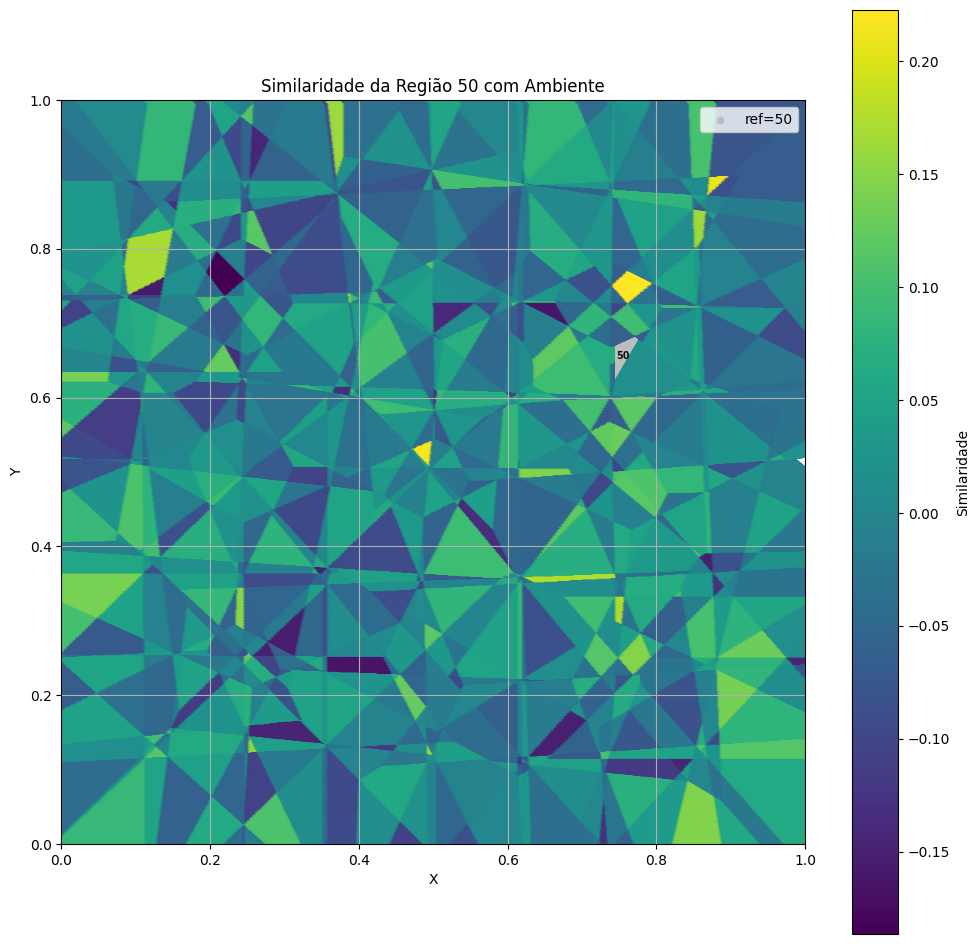

In [14]:
plot_similarity_to_group_from_matrix(apd, coss, grupo_ref=50, cmap="viridis", annotate_means=False)

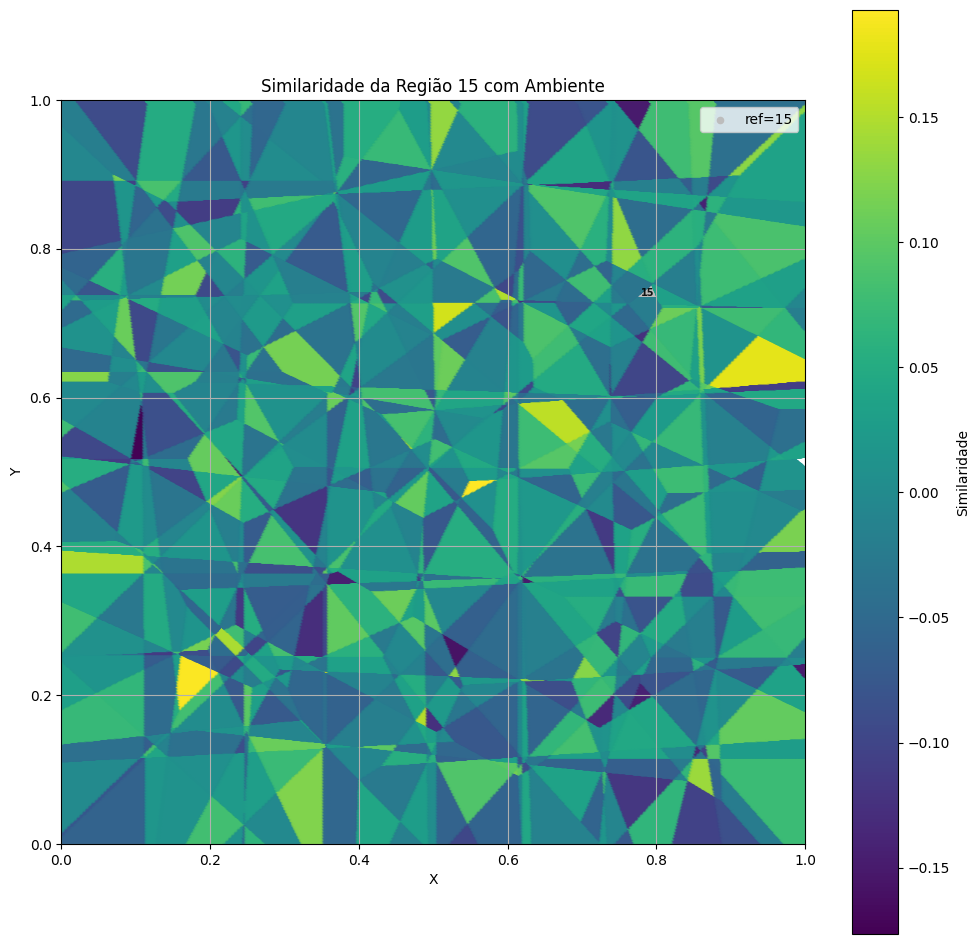

In [24]:
plot_similarity_to_group_from_matrix(apd, coss, grupo_ref=15, cmap="viridis", annotate_means=False)

# Head Projections

In [ ]:
def plot_similarity_to_group_from_projec_matrix(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head:int = 0,
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente [Head {num_head}]")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()

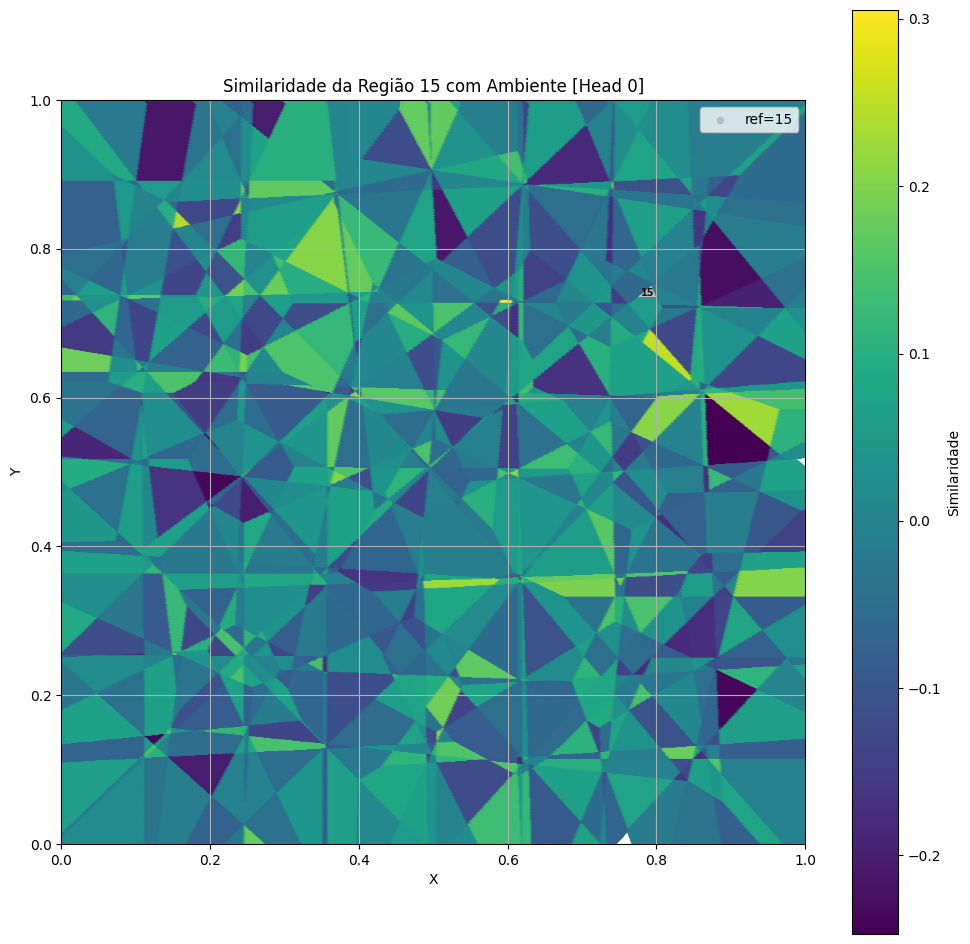

In [19]:
plot_similarity_to_group_from_projec_matrix(apd, head0, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=0)

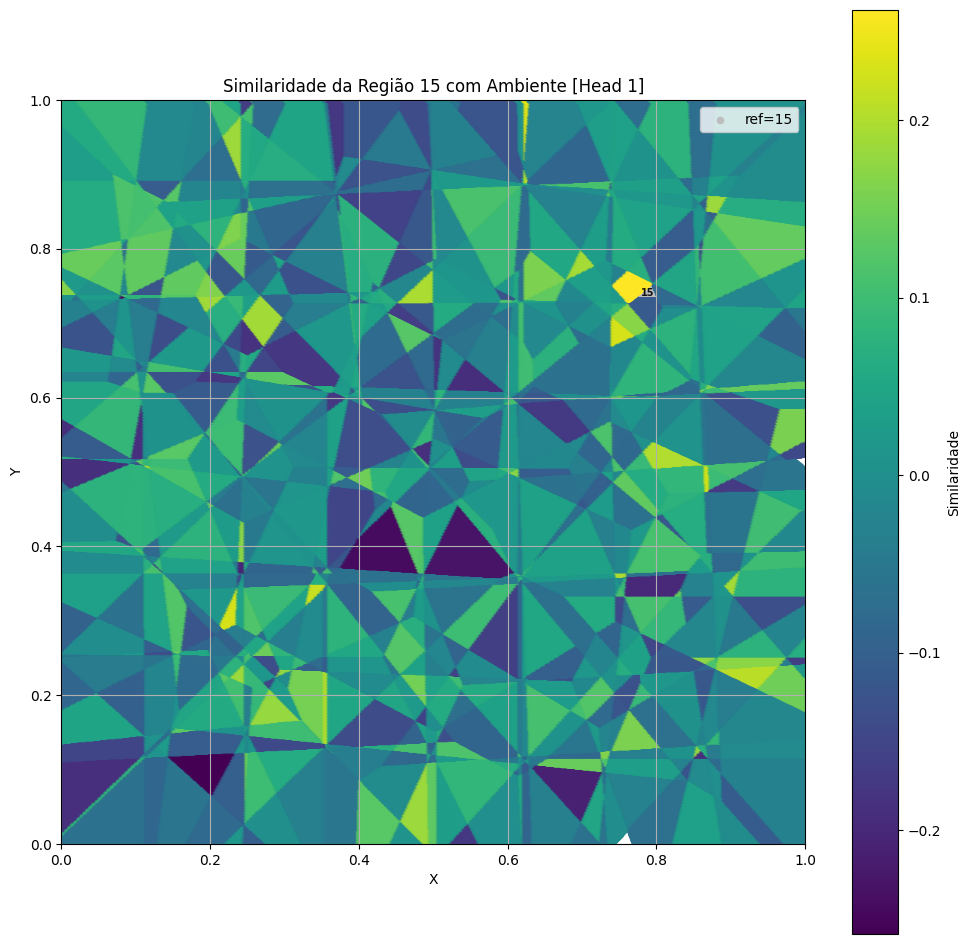

In [20]:
plot_similarity_to_group_from_projec_matrix(apd, head1, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=1)

# Head Attentions

In [10]:
def plot_similarity_to_group_from_attn_matrix(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head:int = 0,
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente [Head {num_head}]")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()

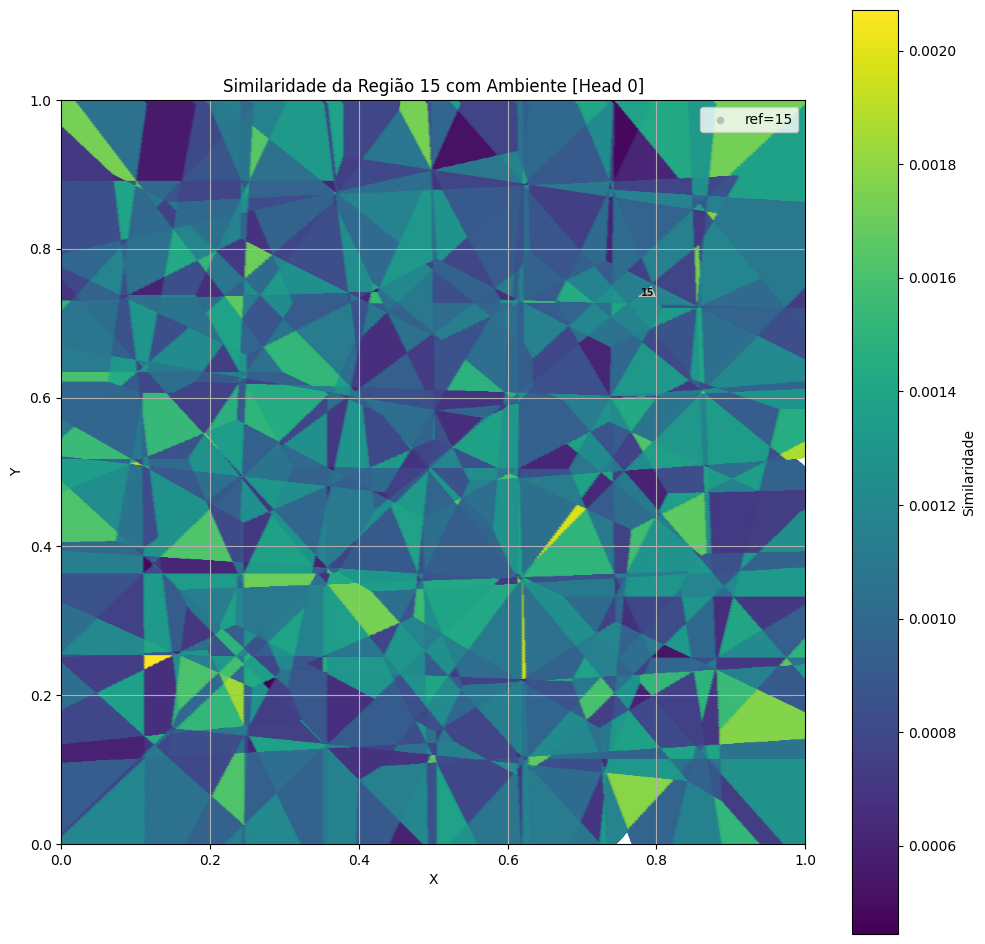

In [11]:
plot_similarity_to_group_from_attn_matrix(apd, head0_att, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=0)

In [14]:
apd['position_state_id'].max()

1056

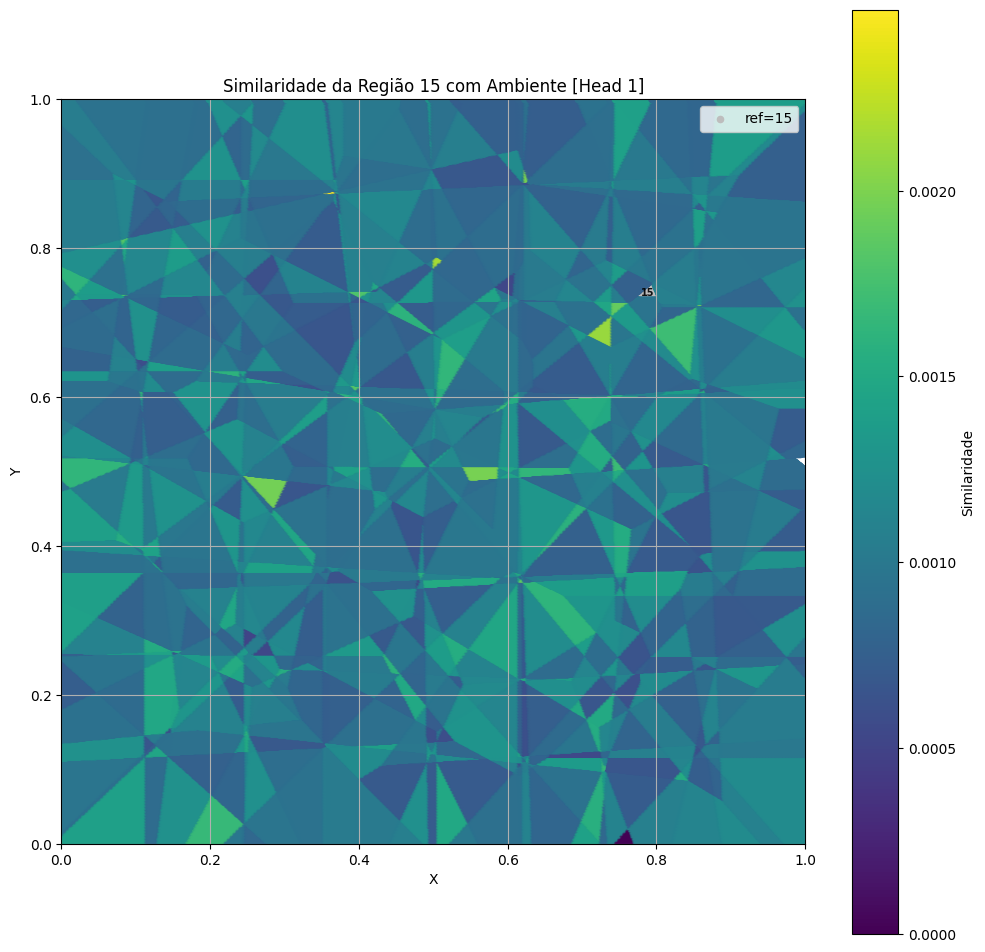

In [12]:
plot_similarity_to_group_from_attn_matrix(apd, head1_att, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=1)

# Head Attn w Pos

In [13]:
def plot_similarity_to_group_from_attn_matrix_w_pos(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head:int = 0,
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente [Head {num_head}]")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()

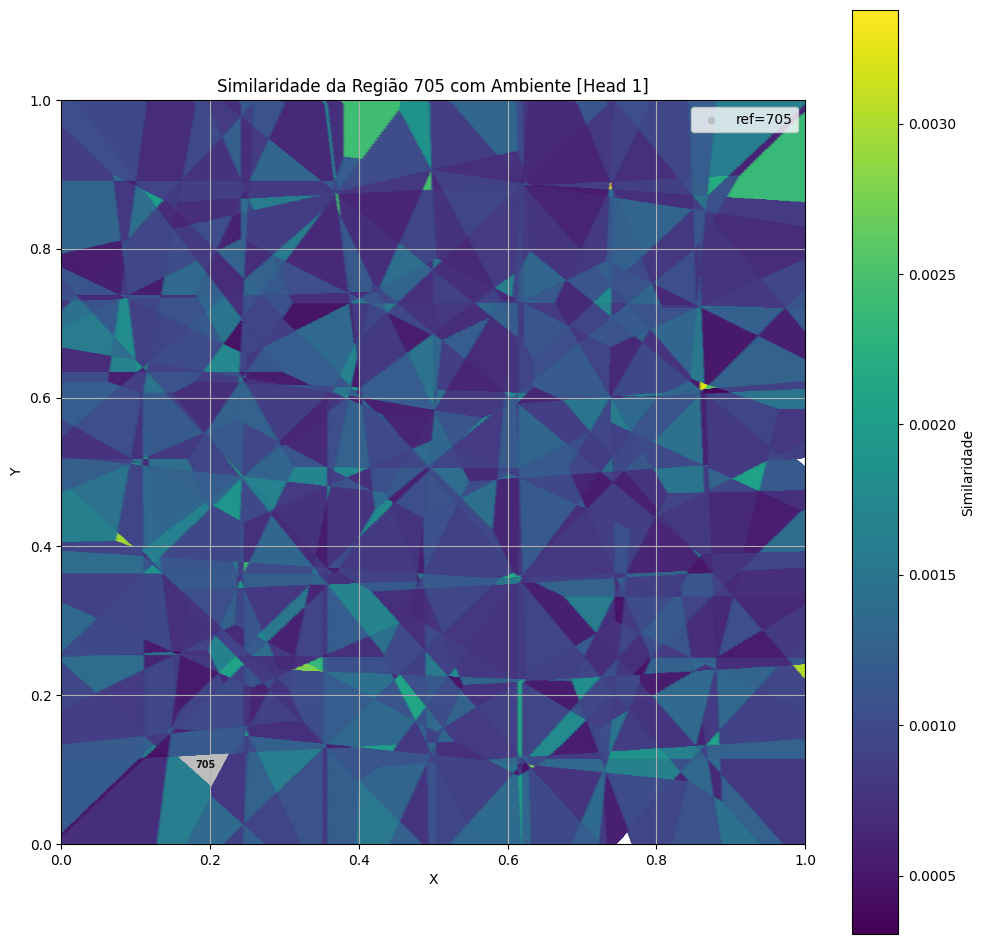

In [22]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head1_att_pos, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=1)

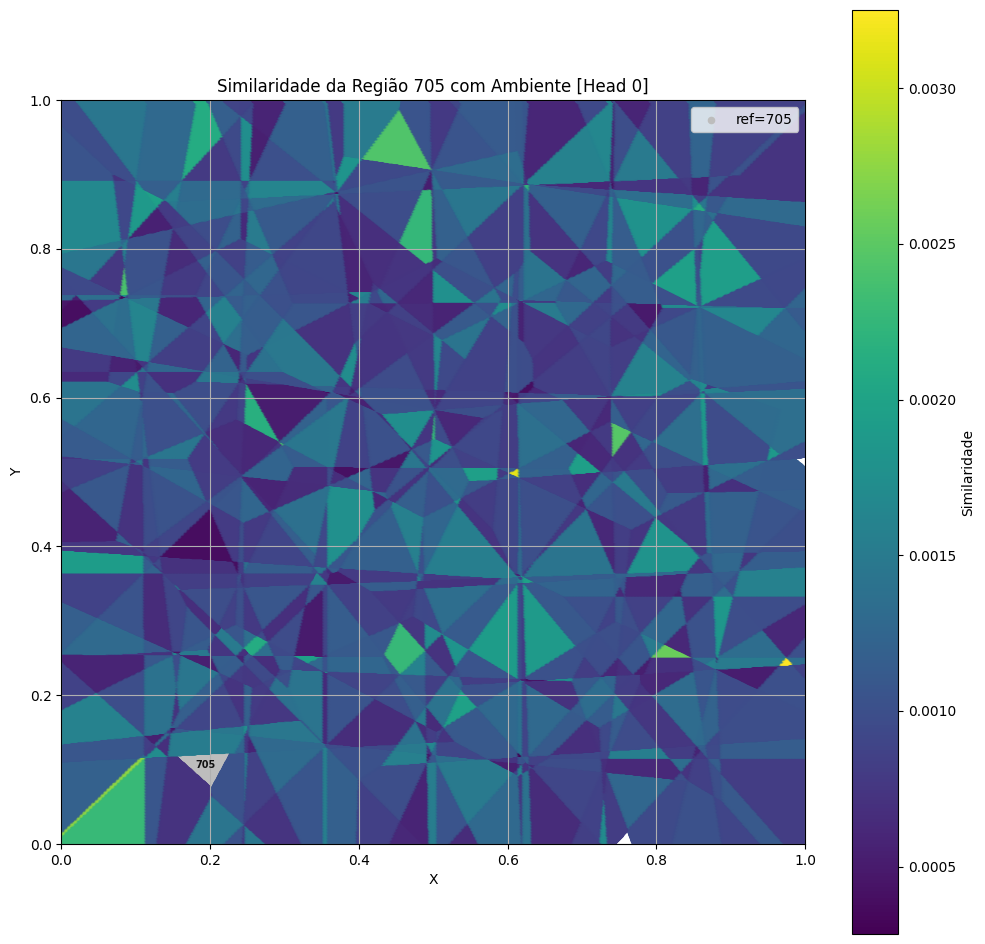

In [23]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head0_att_pos, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=0)

In [19]:
# plot_similarity_to_group_from_attn_matrix(apd, head1_att_pos, grupo_ref=806, cmap="viridis", annotate_means=False, num_head=1)

In [ ]:
head1_att_pos.iloc[705].sort_values(ascending=False).head()

341    0.002764
210    0.002684
770    0.002652
667    0.002426
775    0.002383
Name: 15, dtype: float64

In [ ]:
head0_att_pos.iloc[705].sort_values(ascending=False).head()

808    0.004574
138    0.003253
743    0.002719
624    0.002260
446    0.002227
Name: 15, dtype: float64

In [ ]:
head1_att_pos.iloc[15]['806']

0.0027919996

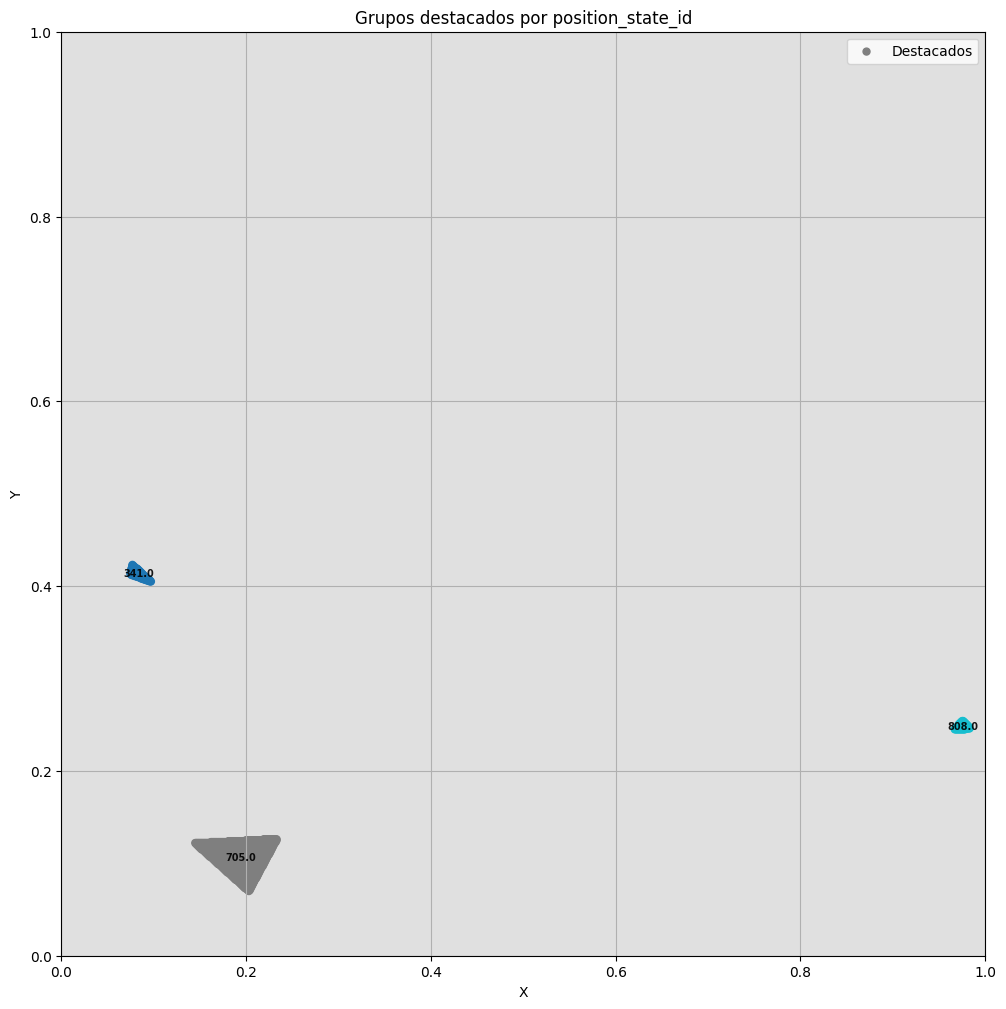

: 

In [ ]:
plot_position_states(apd, [705, 341, 808])

# FIM